# k-NN vs Voting V4

For V4, I wanted to see if changing the image features could improve k-NN. I took the square root of each feature, normalized each image, and compared k-NN alone with the conditional vote from V3.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

result_dir = project_root / 'results/model_comparison'
result_dir.mkdir(parents=True, exist_ok=True)

I loaded the same image split and checked the saved V2, V3 and NN predictions against the validation labels.

In [2]:
X, y, X_test, test_ids = load_task('image')
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
assert X_train.shape == (16000, 500) and X_val.shape == (4000, 500)
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
assert X.dtype == X_train.dtype == X_val.dtype == X_test.dtype == np.float32
raw_knn = pd.read_csv(result_dir / 'knn_vs_voting_v2_knn16k_validation.csv')
raw_vote = pd.read_csv(result_dir / 'knn_vs_voting_v3_image_validation.csv')
nn3 = pd.read_csv(project_root / 'results/image/nn_v3_validation.csv')
nn4 = pd.read_csv(project_root / 'results/image/nn_v4_validation.csv')
for frame in [raw_knn, raw_vote, nn3, nn4]:
    assert frame.columns.tolist() == ['validation_index', 'actual_label', 'predicted_label']
    assert len(frame) == 4000 and not frame.isna().any().any()
    assert frame.validation_index.is_unique
    assert np.array_equal(frame.validation_index, np.arange(4000))
    assert np.array_equal(frame.actual_label, y_val)
    for column in frame.columns:
        assert pd.api.types.is_integer_dtype(frame[column])
    assert frame.actual_label.between(0, 49).all() and frame.predicted_label.between(0, 49).all()

I transformed the training and validation images separately, then calculated their nearest neighbors using the same k-NN settings.

In [3]:
def sqrt_features(features):
    assert np.isfinite(features).all() and (features >= 0).all()
    transformed = np.sqrt(features)
    lengths = np.linalg.norm(transformed, axis=1, keepdims=True)
    assert (lengths > 0).all()
    transformed = transformed / lengths
    assert transformed.shape == features.shape and transformed.dtype == np.float32
    assert np.allclose(np.linalg.norm(transformed, axis=1), 1, atol=1e-6)
    return transformed

def nearest_images(model, features):
    nearest_distances = []
    nearest_labels = []
    for image in features:
        distances = euclidean_distance(image, model.X_train)
        nearest = int(np.argmin(distances))
        nearest_distances.append(distances[nearest])
        nearest_labels.append(model.y_train[nearest])
    return np.asarray(nearest_distances), np.asarray(nearest_labels)


train_transformed = sqrt_features(X_train)
val_transformed = sqrt_features(X_val)
model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
model.fit(train_transformed, y_train)
start = perf_counter()
validation_distances, knn_predictions = nearest_images(model, val_transformed)
assert len(validation_distances) == len(knn_predictions) == 4000
assert np.isfinite(validation_distances).all() and validation_distances.dtype == np.float32
assert np.array_equal(model.predict(val_transformed[:5]), knn_predictions[:5])
assert pd.api.types.is_integer_dtype(knn_predictions)
assert ((knn_predictions >= 0) & (knn_predictions <= 49)).all()
knn_validation = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'predicted_label': knn_predictions})
knn_validation.to_csv(result_dir / 'knn_vs_voting_v4_knn_validation.csv', index=False)
cutoff = np.percentile(validation_distances[:2000], 85)
print('Transformed validation distance cutoff:', cutoff)
print(f'Validation neighbors calculated in {perf_counter() - start:.6f} s')

Transformed validation distance cutoff: 1.135142457485199
Validation neighbors calculated in 141.030378 s


Then I applied the V3 agreement rule using the cutoff from the transformed validation distances.

In [4]:
def conditional_vote(knn_labels, distances, nn3_labels, nn4_labels, cutoff):
    assert len(knn_labels) == len(distances) == len(nn3_labels) == len(nn4_labels)
    use_nn = (distances >= cutoff) & (nn3_labels == nn4_labels)
    predictions = knn_labels.copy()
    predictions[use_nn] = nn3_labels[use_nn]
    return predictions, use_nn


v4_predictions, use_nn = conditional_vote(
    knn_predictions, validation_distances, nn3.predicted_label.to_numpy(),
    nn4.predicted_label.to_numpy(), cutoff)
assert np.array_equal(v4_predictions[~use_nn], knn_predictions[~use_nn])
assert np.array_equal(v4_predictions[use_nn], nn3.predicted_label.to_numpy()[use_nn])
assert ((v4_predictions >= 0) & (v4_predictions <= 49)).all()
validation = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'predicted_label': v4_predictions})
validation.to_csv(result_dir / 'knn_vs_voting_v4_image_validation.csv', index=False)
print('Image labels changed by the conditional vote:', int((v4_predictions != knn_predictions).sum()))

Image labels changed by the conditional vote: 218


I compared the new predictions with V2 and V3, then looked at both halves of the same validation set.

In [5]:
rows = []
for name, predictions, setting in [
    ('V2 raw k-NN', raw_knn.predicted_label.to_numpy(), 'Original features; k=1; 16000 training images'),
    ('V3 raw conditional vote', raw_vote.predicted_label.to_numpy(), 'Original features; NN V3/V4 agreement above the distance cutoff'),
    ('V4 transformed k-NN', knn_predictions, 'Square root and row L2 normalization; k=1; 16000 training images'),
    ('V4 transformed conditional vote', v4_predictions, 'Transformed features; NN V3/V4 agreement at or above the 85th percentile of the first 2000 validation distances')]:
    correct = int((predictions == y_val).sum())
    rows.append({'candidate': name, 'correct_count': correct, 'validation_samples': len(y_val),
                 'validation_accuracy': correct / len(y_val), 'setting': setting})
summary = pd.DataFrame(rows)
summary.to_csv(result_dir / 'knn_vs_voting_v4_summary.csv', index=False)
print(summary[['candidate', 'correct_count', 'validation_samples', 'validation_accuracy']].to_string(index=False))
for start, end in [(0, 2000), (2000, 4000)]:
    old_correct = int((raw_vote.predicted_label.to_numpy()[start:end] == y_val[start:end]).sum())
    new_correct = int((v4_predictions[start:end] == y_val[start:end]).sum())
    print(f'Validation positions {start}..{end-1}: V3={old_correct}, V4={new_correct}, gain={new_correct-old_correct}')

                      candidate  correct_count  validation_samples  validation_accuracy
                    V2 raw k-NN           2077                4000              0.51925
        V3 raw conditional vote           2102                4000              0.52550
            V4 transformed k-NN           2252                4000              0.56300
V4 transformed conditional vote           2290                4000              0.57250
Validation positions 0..1999: V3=1021, V4=1140, gain=119
Validation positions 2000..3999: V3=1081, V4=1150, gain=69


I plotted the four image accuracies to compare the transformation with the earlier results.

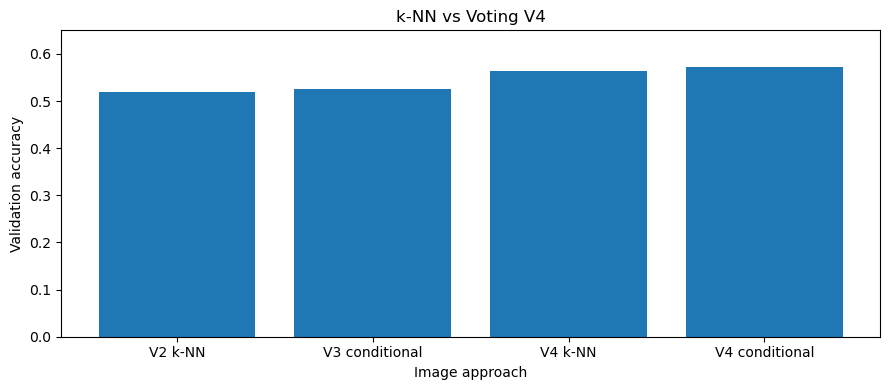

In [6]:
plt.figure(figsize=(9, 4))
plt.bar(['V2 k-NN', 'V3 conditional', 'V4 k-NN', 'V4 conditional'], summary.validation_accuracy)
plt.xlabel('Image approach')
plt.ylabel('Validation accuracy')
plt.title('k-NN vs Voting V4')
plt.ylim(0, 0.65)
plt.tight_layout()
plt.savefig(result_dir / 'knn_vs_voting_v4_accuracy.png')
plt.show()

I kept NN V3 for sentiment and calculated the equal average of the two task accuracies.

In [7]:
sentiment = pd.read_csv(project_root / 'results/sentiment/nn_v3_validation.csv')
raw_sentiment_labels = pd.read_csv(project_root / 'data/raw/sentiment_train.csv', usecols=['label']).label.to_numpy()
_, _, _, sentiment_y_val = split_train_val(
    np.arange(len(raw_sentiment_labels)).reshape(-1, 1), raw_sentiment_labels,
    val_fraction=0.2, seed=42)
assert len(sentiment) == 2400 and not sentiment.isna().any().any()
assert sentiment.validation_index.is_unique
assert np.array_equal(sentiment.validation_index, np.arange(2400))
assert np.array_equal(sentiment.actual_label, sentiment_y_val)
for column in ['validation_index', 'actual_label', 'predicted_label']:
    assert pd.api.types.is_integer_dtype(sentiment[column])
assert sentiment.predicted_label.between(0, 2).all()
sentiment_correct = int((sentiment.predicted_label == sentiment.actual_label).sum())
sentiment_accuracy = sentiment_correct / len(sentiment)
image_accuracy = float((v4_predictions == y_val).mean())
combined_accuracy = (image_accuracy + sentiment_accuracy) / 2
print(f'NN V3 sentiment: {sentiment_correct}/{len(sentiment)}, accuracy={sentiment_accuracy!r}')
print('Combined validation accuracy:', combined_accuracy)

NN V3 sentiment: 1639/2400, accuracy=0.6829166666666666
Combined validation accuracy: 0.6277083333333333


I applied the same transformation to all the training and test images, then calculated the test neighbors and a separate 85th-percentile cutoff.

In [8]:
all_transformed = sqrt_features(X)
test_transformed = sqrt_features(X_test)
test_model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
test_model.fit(all_transformed, y)
start = perf_counter()
test_distances, test_knn_labels = nearest_images(test_model, test_transformed)
assert len(test_distances) == len(test_knn_labels) == len(test_ids) == 5000
assert np.isfinite(test_distances).all() and test_distances.dtype == np.float32
assert np.array_equal(test_model.predict(test_transformed[:5]), test_knn_labels[:5])
test_cutoff = np.percentile(test_distances, 85)
print('Transformed test distance cutoff:', test_cutoff)
print(f'Test neighbors calculated in {perf_counter() - start:.6f} s')

Transformed test distance cutoff: 1.129971808195114
Test neighbors calculated in 233.389284 s


I matched NN V3 and V4 by image ID and applied the same conditional rule.

In [9]:
sample = pd.read_csv(project_root / 'data/raw/sample_submission.csv')
text_ids = pd.read_csv(project_root / 'data/raw/sentiment_test.csv', usecols=['id']).id
assert sample.columns.tolist() == ['id', 'label']
assert len(sample) == 10000 and sample.id.is_unique and not sample.isna().any().any()
assert len(set(test_ids)) == 5000 and len(text_ids) == 5000 and text_ids.is_unique
assert all(str(sample_id).startswith('img_') for sample_id in test_ids)
assert text_ids.str.startswith('text_').all()
assert set(test_ids).isdisjoint(set(text_ids))
assert set(sample.id) == set(test_ids) | set(text_ids)
is_image = sample.id.isin(test_ids)
is_text = sample.id.isin(text_ids)

def align_submission(path, ids):
    frame = pd.read_csv(path)
    assert frame.columns.tolist() == ['id', 'label']
    assert len(frame) == 10000 and frame.id.is_unique and not frame.isna().any().any()
    assert set(frame.id) == set(sample.id)
    assert pd.api.types.is_integer_dtype(frame.label)
    assert frame.loc[frame.id.isin(test_ids), 'label'].between(0, 49).all()
    assert frame.loc[frame.id.isin(text_ids), 'label'].between(0, 2).all()
    aligned = pd.DataFrame({'id': ids}).merge(frame, on='id', how='left', sort=False, validate='one_to_one')
    assert aligned.id.tolist() == list(ids) and not aligned.isna().any().any()
    return aligned

nn3_images = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', test_ids)
nn4_images = align_submission(project_root / 'submission/nn/submission_v4_nn.csv', test_ids)
test_predictions, test_use_nn = conditional_vote(test_knn_labels, test_distances,
    nn3_images.label.to_numpy(), nn4_images.label.to_numpy(), test_cutoff)
assert np.array_equal(test_predictions[~test_use_nn], test_knn_labels[~test_use_nn])
assert np.array_equal(test_predictions[test_use_nn], nn3_images.label.to_numpy()[test_use_nn])
print('Image labels changed from transformed k-NN:', int((test_predictions != test_knn_labels).sum()))

Image labels changed from transformed k-NN: 242


Finally, I combined the new image predictions with NN V3 sentiment and saved the Kaggle CSV.

In [10]:
image_predictions = pd.DataFrame({'id': test_ids, 'label': test_predictions})
sentiment_predictions = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', text_ids)
predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
assert len(predictions) == 10000 and predictions.id.is_unique
submission = sample[['id']].merge(predictions, on='id', how='left', sort=False, validate='one_to_one')
assert submission.columns.tolist() == ['id', 'label']
assert submission.id.tolist() == sample.id.tolist()
assert not submission.isna().any().any() and pd.api.types.is_integer_dtype(submission.label)
assert is_image.sum() == is_text.sum() == 5000
assert submission.loc[is_image, 'label'].between(0, 49).all()
assert submission.loc[is_text, 'label'].between(0, 2).all()
assert np.array_equal(submission.loc[is_text, 'label'],
    align_submission(project_root / 'submission/nn/submission_v3_nn.csv', sample.id).loc[is_text, 'label'])
previous = align_submission(project_root / 'submissions/submission_knn_vs_voting_v3.csv', sample.id)
changed = submission.label != previous.label
changed_images = int((changed & is_image).sum())
changed_sentiment = int((changed & is_text).sum())
print('Changed image labels compared with V3:', changed_images)
print('Changed sentiment labels compared with V3:', changed_sentiment)
assert changed_images > 0 and changed_sentiment == 0
submission_dir = project_root / 'submissions'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_knn_vs_voting_v4.csv'
submission.to_csv(submission_path, index=False)
assert pd.read_csv(submission_path).equals(submission)
print('Saved', len(submission), 'predictions to', submission_path.relative_to(project_root))

Changed image labels compared with V3: 1510
Changed sentiment labels compared with V3: 0
Saved 10000 predictions to submissions\submission_knn_vs_voting_v4.csv


The square-root features gave k-NN 56.300% accuracy, and the conditional vote reached 57.250%. I kept NN V3 for sentiment and will compare the Kaggle result before deciding which approach to keep.